## Dataset CDCP

CDCP (também conhecido como *Cornell eRulemaking Corpus*; [Park and Cardie, 2018](https://aclanthology.org/L18-1257.pdf)) consiste em 731 comentários de usuários de uma plataforma de eRulemaking, em língua inglesa. Há cinco tipos de componentes (`fact`, `testimony`, `reference`, `value` e `policy`) e dois tipos de relações de suporte (`reason` e `evidence`), anotados com base no estudo de Park et al. (2015). O conjunto de dados resultante contém 4.931 unidades elementares e 1.221 anotações de relações de suporte (pp. 1623–1624). Os trechos são segmentados em unidades elementares, sendo que cada proposição consiste em uma sentença ou oração, além de algumas unidades não argumentativas (Morio et al., 2022, p. 642).


In [290]:
from pathlib import Path
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from tabulate import tabulate
import json

In [217]:
result_path = "./results/cdcp/"
root_path = "./dataset_cdcp/cdcp/"
path_train = root_path + "train"
path_test = root_path + "test"

In [152]:
path = Path(path_train)
text_file_names_train = list(path.glob("*.txt"))
path = Path(path_test)
text_file_names_test = list(path.glob("*.txt"))

print("Cantidad de archivos train:", len(text_file_names_train))
print("Cantidad de archivos test:", len(text_file_names_test))
print(F"Total: {len(text_file_names_train) + len(text_file_names_test)}")

Cantidad de archivos train: 581
Cantidad de archivos test: 150
Total: 731


In [129]:
def generate_examples(path):
        """Yields examples."""
        # This method will receive as arguments the `gen_kwargs` defined in the previous `_split_generators` method.
        # It is in charge of opening the given file and yielding (key, example) tuples from the dataset
        # The key is not important, it's more here for legacy reason (legacy from tfds)

        _id = 0
        examples = []
        text_file_names = sorted(glob.glob(f"{path}/*.txt"))
        for text_file_name in text_file_names:
            txt_fn = Path(text_file_name)
            ex_id = txt_fn.stem
            if ex_id == "00411":
                continue  # this example is broken (same text as 00410, but with missing some annotations)
            ann_fn = txt_fn.with_suffix(".ann.json")
            with open(txt_fn, encoding="utf-8") as f:
                text = f.read()
            with open(ann_fn, encoding="utf-8") as f:
                annotations = json.load(f)
            # example content of annotations:
            # {
            #   'evidences': [[[8, 8], 7]],
            #   'prop_labels': ['testimony', 'testimony', 'value'],
            #   'prop_offsets': [[0, 114], [114, 209], [209, 235]],
            #   'reasons': [[[2, 2], 1], [ 0, 0], 2]],
            #   'evidences': [[[2, 2], 1], [ 0, 0], 2]],
            #   'url': {
            #       "3": "http://usa.visa.com/personal/using_visa/checkout_fees/",
            #       "4": "http://usa.visa.com/download/merchants/surcharging-faq-by-merchants.pdf"
            #   }
            # }
            propositions = [
                {
                    "start": start,
                    "end": end,
                    "label": label,
                    "url": annotations["url"].get(str(idx), ""),
                }
                for idx, ((start, end), label) in enumerate(
                    zip(annotations["prop_offsets"], annotations["prop_labels"])
                )
            ]
            relations = []
            for (tail_first_idx, tail_last_idx), head_idx in annotations["evidences"]:
                for tail_idx in range(tail_first_idx, tail_last_idx + 1):
                    relations.append({"head": head_idx, "tail": tail_idx, "label": "evidence"})
            for (tail_first_idx, tail_last_idx), head_idx in annotations["reasons"]:
                for tail_idx in range(tail_first_idx, tail_last_idx + 1):
                    relations.append({"head": head_idx, "tail": tail_idx, "label": "reason"})
            examples.append({
                "id": ex_id,
                "text": text,
                "propositions": propositions,
                "relations": relations,
            })
            _id += 1
        return examples

In [219]:
examples_train = generate_examples(path_train)
examples_test = generate_examples(path_test)

examples = examples_train + examples_test
total_propositions = sum(len(x["propositions"]) for x in examples)
total_relations = sum(len(x["relations"]) for x in examples)

# examples = examples_train
# total_propositions_train = sum(len(x["propositions"]) for x in examples)
# total_relations_train = sum(len(x["relations"]) for x in examples)

df = pd.DataFrame([{
    "total_elements": len(examples),
    "total_propositions": total_propositions,
    "total_relations": total_relations
}])

df


,total_elements,total_propositions,total_relations
0,730,4927,1426


In [283]:
# Revisar os componentes por text_id
example_graph = [x for x in examples if x["id"] == "00602"]
example_graph

[{'id': '00602',
  'text': 'Is it possible to just allow consumers to opt out of certain kinds of communication entirely? They could set transparent, limited rate increases which debt collectors could charge for each mode of communication that is eliminated. A rule setting that kind of rate increase would add some necessary transparency to the question of whether these kinds of communications are even worthwhile for the agency.',
  'propositions': [{'start': 0, 'end': 93, 'label': 'value', 'url': ''},
   {'start': 93, 'end': 230, 'label': 'policy', 'url': ''},
   {'start': 230, 'end': 403, 'label': 'value', 'url': ''}],
  'relations': [{'head': 1, 'tail': 2, 'label': 'reason'}]}]

In [284]:
texto = example_graph[0]["text"]
print(texto[0:93])
print(texto[93:230])
print(texto[230:403])
# print(texto[342:356])
# print(texto[356:384])
# print(texto[384:424])
# print(texto[424:455])
# print(texto[455:545])
# print(texto[545:561])

Is it possible to just allow consumers to opt out of certain kinds of communication entirely?
 They could set transparent, limited rate increases which debt collectors could charge for each mode of communication that is eliminated.
 A rule setting that kind of rate increase would add some necessary transparency to the question of whether these kinds of communications are even worthwhile for the agency.


In [285]:
# Só ids dos exemplos

df_examples_summary = pd.DataFrame([
    {
        "id": x["id"],
        "nós": len(x["propositions"]),
        "arestas": len(x["relations"])
    }
    for x in examples
])

print(df_examples_summary.shape)
# df_examples_summary

(730, 3)


In [275]:
rows = []

for example in examples:
    text = example["text"]

    for relation in example["relations"]:
        target_idx = relation["head"]
        source_idx = relation["tail"]

        source_prop = example["propositions"][source_idx]
        target_prop = example["propositions"][target_idx]

        rows.append({
            "id": example["id"],
            "text": text,
            "source_idx": source_idx,
            "proposition_source": text[
                source_prop["start"]:source_prop["end"]
            ].strip(),
            "source_label": source_prop["label"],
            "target_idx": target_idx,
            "proposition_target": text[
                target_prop["start"]:target_prop["end"]
            ].strip(),
            "target_label": target_prop["label"],
            "relation": relation["label"]
        })

df = pd.DataFrame(rows)

# df

In [293]:
# Revisar as relações por text_id
df_filter = df[df["id"] == "00817"]
print(df_filter.shape)
df_filter
# print(tabulate(df_filter.reset_index(), headers='keys', tablefmt='rounded_outline', showindex=False))

(5, 9)


,id,text,source_idx,proposition_source,source_label,target_idx,proposition_target,target_label,relation
559,00817,If you want to instantly level the playing fie...,1,Disputability of any amount over the amount at...,value,0,If you want to instantly level the playing fie...,policy,reason
560,00817,If you want to instantly level the playing fie...,2,"As it stands now, credit card companies can an...",fact,1,Disputability of any amount over the amount at...,value,reason
561,00817,If you want to instantly level the playing fie...,3,and may even let the account stay in default,value,1,Disputability of any amount over the amount at...,value,reason
562,00817,If you want to instantly level the playing fie...,4,as they rack up frequent default points on the...,value,1,Disputability of any amount over the amount at...,value,reason
563,00817,If you want to instantly level the playing fie...,4,as they rack up frequent default points on the...,value,3,and may even let the account stay in default,value,reason


In [264]:
valores_unicos = (
    pd.unique(
        df_filter[["proposition_source", "proposition_target"]].values.ravel()
    )
    .tolist()
)

# for vn in valores_unicos:
#     print(vn)

In [225]:
def crear_grafo(text_id, df_text):
    # Filtrar datos del text_id
    df_sub = df_text[df_text["id"] == text_id]
    
    # Crear grafo dirigido
    G = nx.DiGraph()
    
    for _, row in df_sub.iterrows():
        # if row["relation"] != 0:
        G.add_edge(row["source_idx"], row["target_idx"], label=row["relation"])
    
    # Metricas, numero de componentes e nós isolados
    n_comp     = nx.number_weakly_connected_components(G)
    n_isolates = nx.number_of_isolates(G)
    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()
    return pd.Series({
        "graph":       G,
        "n_node":      n_nodes,
        "n_edge":      n_edges,
        "n_comp":      n_comp,
        "n_isolates":  n_isolates
    })

# def plot_grafo(text_id, df_graph):
def plot_grafo(text_id, G):
    # row = df_graph[df_graph["id"] == text_id].iloc[0]
    # G   = row["grafo"]
    
    colores_label = {"evidence": "green", "reason": "red"}
    edge_colors   = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]
    
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, seed=42, k=0.5, iterations=10)
    
    nx.draw_networkx_nodes(G, pos, node_color="steelblue", node_size=2000)
    nx.draw_networkx_labels(G, pos, font_color="black", font_size=8, font_weight="bold")
    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        arrows=True, arrowsize=25, arrowstyle="-|>",
        width=2, connectionstyle="arc3,rad=0.1",
        min_source_margin=30, min_target_margin=30,
    )
    
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9, font_color="black")
    
    from matplotlib.lines import Line2D
    leyenda = [
        Line2D([0], [0], color="green", linewidth=2, label="evidence"),
        Line2D([0], [0], color="red",   linewidth=2, label="reason"),
        Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
    ]
    plt.legend(handles=leyenda, loc="upper left", fontsize=9)
    plt.title(f"Grafo argumentativo: {text_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


### Tabela resumo os dados do grafo

In [294]:
# Uso
df_examples_summary[["graph", "n_nodes", "n_edges", "n_comp", "n_isolates"]] = df_examples_summary["id"].apply(
    lambda id_text: crear_grafo(id_text, df)
)
df_examples_summary.to_csv(result_path + "CDCP_Grafo.csv", index=False)
df_examples_summary

,id,nós,arestas,graph,n_nodes,n_edges,n_comp,n_isolates
0,00195,3,2,"(1, 0, 2)",3,2,1,0
1,00197,4,1,"(0, 3)",2,1,1,0
2,00198,4,1,"(0, 2)",2,1,1,0
3,00200,2,1,"(0, 1)",2,1,1,0
4,00201,10,3,"(3, 2, 6, 5, 9, 8)",6,3,3,0
...,...,...,...,...,...,...,...,...
725,01388,23,2,"(17, 16, 21, 19)",4,2,2,0
726,01398,13,2,"(3, 4, 8, 7)",4,2,2,0
727,01405,2,1,"(1, 0)",2,1,1,0
728,01411,15,8,"(3, 0, 4, 5, 6, 8, 7, 10, 9, 12, 11, 13)",12,8,4,0


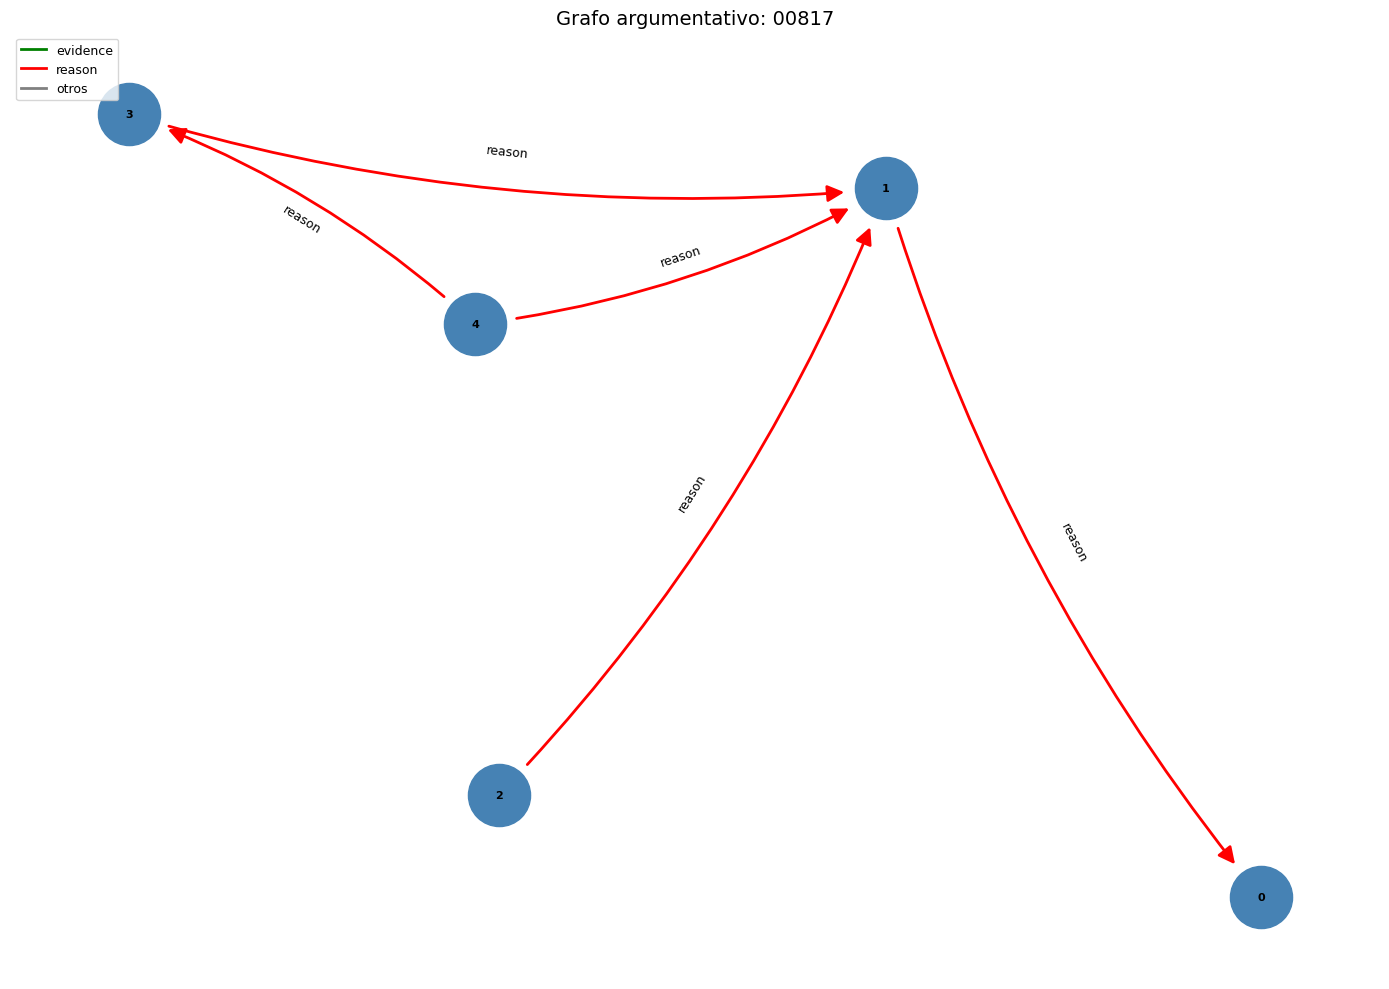

In [295]:
id_text = "00817"
graph = df_examples_summary.loc[df_examples_summary["id"] == id_text, "graph"].iloc[0]
plot_grafo(id_text, graph)